# Credit-Card Fraud Detection — An End-to-End Machine Learning Project

**MILLICENT JEROTICH KEMEI - 224097**

**Dataset:** `creditcard.csv` — 284,807 European card transactions over two days, 492 of them fraudulent.
Features `V1`–`V28` are PCA components (anonymised by the data provider); `Time` is seconds since the first
transaction; `Amount` is the transaction value in euros; `Class` is 1 for fraud.




In [ ]:
import time, json, sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, confusion_matrix, precision_score,
                             recall_score, fbeta_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


## Step 1 — Frame the problem

**Business objective.** A card issuer wants to stop fraudulent transactions before the money is lost, without
burying its fraud-operations team in false alarms or annoying genuine customers.

**ML task.** Supervised binary classification on tabular data: estimate $\hat p(x) = P(\text{fraud} \mid x)$ for every
transaction, then turn that score into a *decision* (block / send for review vs. approve).

* **PR-AUC (average precision)** — the main *ranking* metric; it focuses on the rare positive class.
* **ROC-AUC** — reported for completeness, but it looks flattering under heavy imbalance.
* **Expected cost in euros** — the metric the business actually cares about, used to choose the operating threshold.



In [ ]:
C_FP = 5.0   # euros per false alarm (assumption — edit to match your operation)

def decision_cost(y_true, y_flag, amount, c_fp=C_FP):
    # Total cost in euros: missed fraud loses its amount; each false alarm costs c_fp.
    y_true, y_flag, amount = np.asarray(y_true), np.asarray(y_flag).astype(bool), np.asarray(amount)
    fn_cost = amount[(y_true == 1) & ~y_flag].sum()
    fp_cost = c_fp * ((y_true == 0) & y_flag).sum()
    return fn_cost + fp_cost

## Step 2 — Get and explore the data



In [ ]:
DATA_PATH = "/content/Credit card.csv"
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH} -> {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Loaded /content/Credit card.csv -> 284,807 rows x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "n_unique": df_raw.nunique(),
    "min": df_raw.min(),
    "max": df_raw.max(),
})
n_dup = df_raw.duplicated().sum()
print(f"Missing values in total : {df_raw.isna().sum().sum()}")
print(f"Exact duplicate rows    : {n_dup:,}  ({n_dup/len(df_raw):.2%})")
print(f"  of which fraud        : {df_raw[df_raw.duplicated()]['Class'].sum()}")
print(f"Zero-amount transactions: {(df_raw.Amount == 0).sum():,}")
audit.T

Missing values in total : 0
Exact duplicate rows    : 1,081  (0.38%)
  of which fraud        : 19
Zero-amount transactions: 1,825


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
n_unique,124592,275653,275655,275657,275654,275657,275652,275651,275643,275656,...,275617,275644,275611,275645,275640,275647,275597,275558,32767,2
min,0.0,-56.40751,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.0,0.0
max,172792.0,2.45493,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.50309,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.16,1.0


**Data-quality findings**

* **Completeness:** no missing values, so no imputation is needed.
* **Uniqueness:** about 1,081 exact duplicate rows. Duplicates can leak across a train/test split (the same row
  ends up on both sides) and inflate scores, so we drop them in Step 3.
* **Validity:** `Amount` ≥ 0; some €0 transactions exist (often card-verification checks), so they are kept.
* **Anonymisation:** `V1`–`V28` are already PCA-transformed and centred, so domain feature engineering on them is
  limited. `Time` and `Amount` are the only raw fields.

### 2.2 Class imbalance

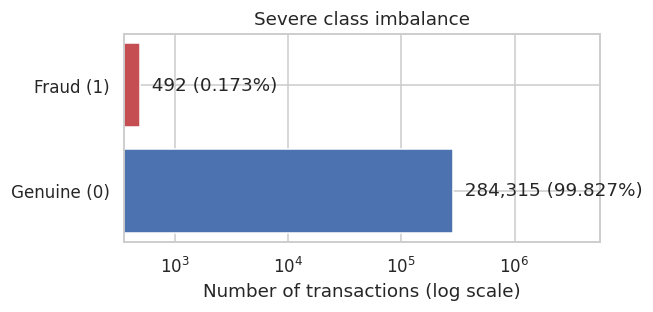

In [ ]:
counts = df_raw["Class"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["Genuine (0)", "Fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_xscale("log"); ax.set_xlabel("Number of transactions (log scale)")
for i, v in enumerate(counts.values):
    ax.text(v, i, f"  {v:,} ({v/counts.sum():.3%})", va="center")
ax.set_title("Severe class imbalance"); ax.set_xlim(right=counts.max()*20)
plt.tight_layout(); plt.show()

### 2.3 Amount and time structure

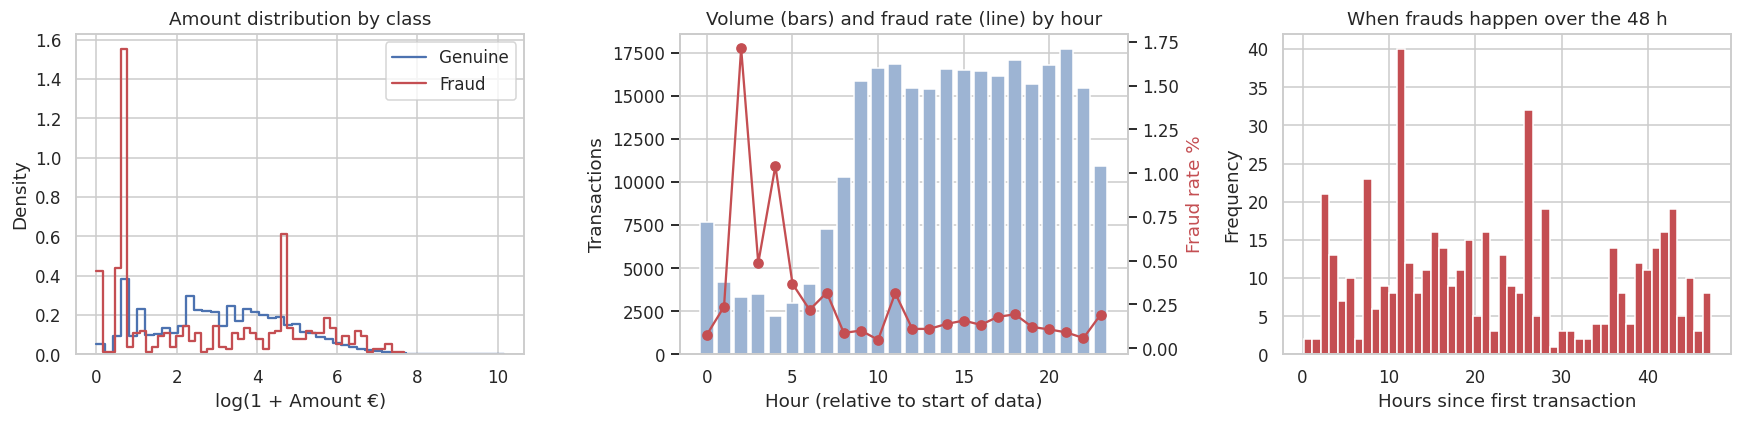

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Amount by class
for cls, col, lab in [(0, "#4C72B0", "Genuine"), (1, "#C44E52", "Fraud")]:
    sns.histplot(np.log1p(df_raw.loc[df_raw.Class == cls, "Amount"]), bins=50, stat="density",
                 element="step", fill=False, color=col, label=lab, ax=axes[0])
axes[0].set_xlabel("log(1 + Amount €)"); axes[0].set_title("Amount distribution by class"); axes[0].legend()

# Transactions and fraud rate by hour (Time is seconds from the first transaction)
hour = (df_raw["Time"] % 86400) // 3600
by_hour = df_raw.groupby(hour)["Class"].agg(["count", "mean"])
axes[1].bar(by_hour.index, by_hour["count"], color="#9DB4D3")
axes[1].set_xlabel("Hour (relative to start of data)"); axes[1].set_ylabel("Transactions")
ax2 = axes[1].twinx(); ax2.plot(by_hour.index, by_hour["mean"]*100, color="#C44E52", marker="o")
ax2.set_ylabel("Fraud rate %", color="#C44E52"); ax2.grid(False)
axes[1].set_title("Volume (bars) and fraud rate (line) by hour")

# Frauds over the two days
df_raw.loc[df_raw.Class == 1, "Time"].div(3600).plot.hist(bins=48, ax=axes[2], color="#C44E52")
axes[2].set_xlabel("Hours since first transaction"); axes[2].set_title("When frauds happen over the 48 h")
plt.tight_layout(); plt.show()

print(df_raw.groupby("Class")["Amount"].describe().round(2))

**Observations**

* Frauds are not especially large: the median fraud amount is *lower* than the median genuine amount, but the
  fraud distribution has a heavy tail. This matters for cost — a few large frauds dominate the losses.
* Transaction volume has a strong daily cycle (a night-time trough), and the **fraud rate rises at night** when
  genuine volume is low. An hour-of-day feature is therefore worth adding.
* The data is a time series. Evaluating on a *random* split would let the model see the future; we use a
  **time-ordered split** instead (the same leakage argument as the rolling-origin backtesting in the sequence-models chapter).

### 2.4 Which features separate the classes?

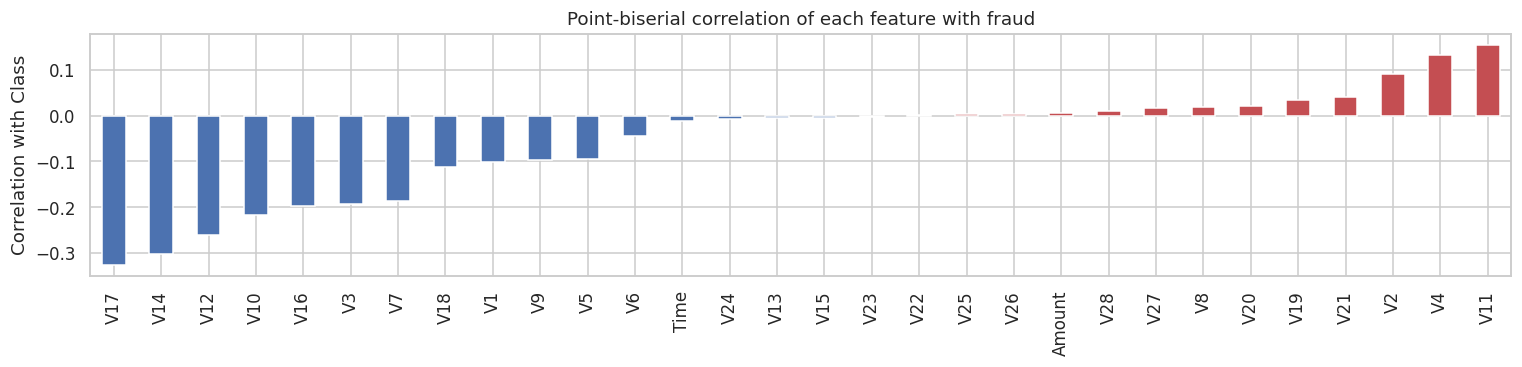

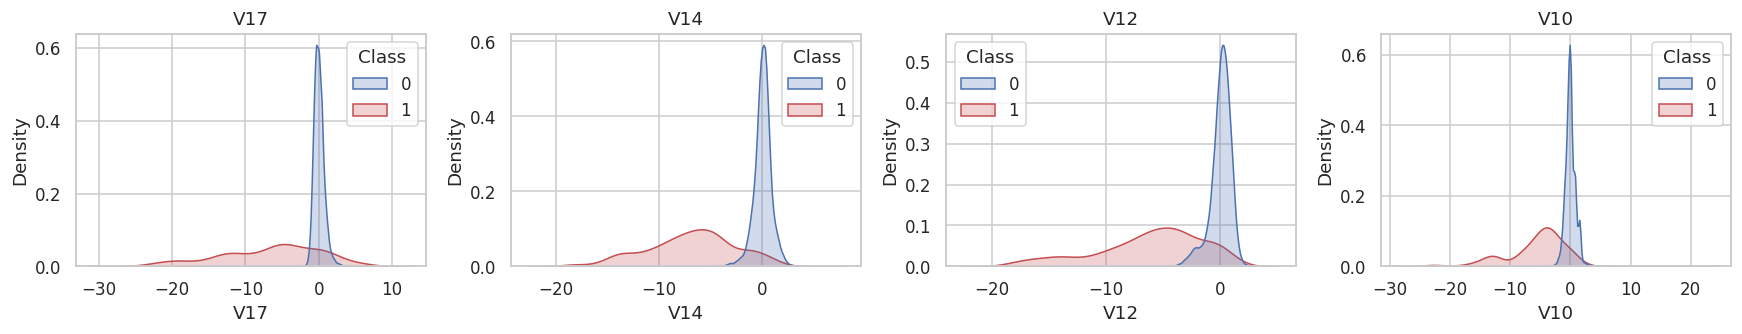

Most informative features: ['V17', 'V14', 'V12', 'V10']


In [ ]:
corr = df_raw.drop(columns=["Class"]).corrwith(df_raw["Class"]).sort_values()
fig, ax = plt.subplots(figsize=(14, 3.5))
corr.plot.bar(ax=ax, color=np.where(corr < 0, "#4C72B0", "#C44E52"))
ax.set_ylabel("Correlation with Class"); ax.set_title("Point-biserial correlation of each feature with fraud")
plt.tight_layout(); plt.show()

top = corr.abs().sort_values(ascending=False).index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, f in zip(axes, top):
    sns.kdeplot(data=df_raw.sample(min(60000, len(df_raw)), random_state=RANDOM_STATE).pipe(lambda d: pd.concat([d, df_raw[df_raw.Class==1]]).reset_index(drop=True)),
                x=f, hue="Class", common_norm=False, fill=True, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(f)
plt.tight_layout(); plt.show()
print("Most informative features:", top)

A handful of PCA components (V14, V17, V12, V10, …) separate frauds strongly. Linear correlation only captures
part of the signal, which is why non-linear models (tree ensembles, MLPs) are on the shortlist.

## Step 3 — Prepare the data

### 3.1 De-duplicate and split by time

* **De-duplicate** before splitting so identical rows cannot sit in both train and test.
* **Time-ordered 60 / 20 / 20 split:** train on the earliest transactions, validate on the next block, and keep
  the latest block as an untouched **test set**, used once at the very end. This mimics deployment: train on the
  past, predict the future.

In [ ]:
df = df_raw.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
print(f"Rows after de-duplication: {len(df):,} (removed {len(df_raw)-len(df):,})")

n = len(df)
i_train, i_val = int(0.60 * n), int(0.80 * n)
train, val, test = df.iloc[:i_train], df.iloc[i_train:i_val], df.iloc[i_val:]

FEATURES_RAW = [c for c in df.columns if c != "Class"]
X_train, y_train = train[FEATURES_RAW], train["Class"].values
X_val,   y_val   = val[FEATURES_RAW],   val["Class"].values
X_test,  y_test  = test[FEATURES_RAW],  test["Class"].values

split_summary = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "frauds": [y_train.sum(), y_val.sum(), y_test.sum()],
    "fraud rate %": [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100],
    "hours from": [train.Time.min()/3600, val.Time.min()/3600, test.Time.min()/3600],
    "hours to": [train.Time.max()/3600, val.Time.max()/3600, test.Time.max()/3600],
}, index=["train", "validation", "test"]).round(2)
split_summary

Rows after de-duplication: 283,726 (removed 1,081)


,rows,frauds,fraud rate %,hours from,hours to
train,170235,342,0.20,0.00,33.44
validation,56745,57,0.10,33.44,40.34
test,56746,74,0.13,40.34,48.00


### 3.2 A leakage-safe feature pipeline

Feature engineering lives in a small Python module (`fraud_features.py`) rather than in a notebook cell. That way
the **same code** runs in training, in the saved model and in the scoring API, which prevents training/serving skew


Engineered features:
* `log_amount = log(1 + Amount)` — tames the heavy right tail
* `hour_sin`, `hour_cos` — cyclical encoding of the hour of day, so 23:00 and 00:00 sit close together.
* Raw `Time` is **dropped**: it only counts seconds since the start of the data and would not generalise to the future.

Scaling, where a model needs it, is fitted *inside* the pipeline on training data only.

In [ ]:
%%writefile fraud_features.py
'''Feature engineering for the fraud model. Imported by training, the saved model and the API.'''
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

V_COLS = [f"V{i}" for i in range(1, 29)]
RAW_COLS = ["Time"] + V_COLS + ["Amount"]
OUT_COLS = V_COLS + ["log_amount", "hour_sin", "hour_cos"]


class FraudFeatures(BaseEstimator, TransformerMixin):
    '''Stateless transformer: raw transaction columns -> model features.'''

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=RAW_COLS)
        missing = set(RAW_COLS) - set(X.columns)
        if missing:
            raise ValueError(f"Missing input columns: {sorted(missing)}")
        out = X[V_COLS].astype(float).copy()
        out["log_amount"] = np.log1p(X["Amount"].astype(float).clip(lower=0))
        hour = (X["Time"].astype(float) % 86400) / 3600.0
        out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
        out["hour_cos"] = np.cos(2 * np.pi * hour / 24)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(OUT_COLS)

Overwriting fraud_features.py


In [ ]:
import importlib, fraud_features
importlib.reload(fraud_features)
from fraud_features import FraudFeatures, OUT_COLS

FraudFeatures().fit_transform(X_train).head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,log_amount,hour_sin,hour_cos
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,5.014760,0.000000,1.0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,1.305626,0.000000,1.0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,5.939276,0.000073,1.0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,4.824306,0.000073,1.0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,4.262539,0.000145,1.0


## Step 4 — Shortlist models

We train one model, quickly and with sensible defaults, and compare them
on the **validation** set. The test set is not touched.



In [ ]:
def scores_of(model, X):
    # Higher score = more likely fraud.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return -model.score_samples(X)          # IsolationForest: lower score_samples = more anomalous

def rank_metrics(y, s):
    return {"PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s)}

shortlist = {
    "Dummy (prior)": make_pipeline(FraudFeatures(), DummyClassifier(strategy="prior")),
    "Logistic regression": make_pipeline(FraudFeatures(), StandardScaler(),
                                         LogisticRegression(max_iter=3000, class_weight="balanced", C=0.1)),
    "Random Forest": make_pipeline(FraudFeatures(),
                                   RandomForestClassifier(n_estimators=200, min_samples_leaf=3, max_features="sqrt",
                                                          class_weight="balanced_subsample", n_jobs=-1,
                                                          random_state=RANDOM_STATE)),
    "Gradient boosting (HGB)": make_pipeline(FraudFeatures(),
                                             HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                                            random_state=RANDOM_STATE)),
    "MLP": make_pipeline(FraudFeatures(), StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                       max_iter=200, random_state=RANDOM_STATE)),
    "Isolation Forest (unsupervised)": make_pipeline(FraudFeatures(),
                                                     IsolationForest(n_estimators=300, random_state=RANDOM_STATE,
                                                                     n_jobs=-1)),
}

results, val_scores, fitted = [], {}, {}
for name, model in shortlist.items():
    t0 = time.time()
    if "Isolation" in name:
        model.fit(X_train)                  # no labels used
    else:
        model.fit(X_train, y_train)
    secs = time.time() - t0
    s = scores_of(model, X_val)
    fitted[name], val_scores[name] = model, s
    results.append({"model": name, **rank_metrics(y_val, s), "fit seconds": round(secs, 1)})
    print(f"{name:34s} PR-AUC={results[-1]['PR-AUC']:.3f}  ({secs:.0f}s)")

shortlist_table = pd.DataFrame(results).set_index("model").sort_values("PR-AUC", ascending=False)
shortlist_table.round(3)

Dummy (prior)                      PR-AUC=0.001  (0s)
Logistic regression                PR-AUC=0.752  (1s)
Random Forest                      PR-AUC=0.768  (209s)
Gradient boosting (HGB)            PR-AUC=0.427  (1s)
MLP                                PR-AUC=0.751  (12s)
Isolation Forest (unsupervised)    PR-AUC=0.024  (1s)


,PR-AUC,ROC-AUC,fit seconds
model,,,
Random Forest,0.768,0.957,209.3
Logistic regression,0.752,0.973,1.1
MLP,0.751,0.912,11.5
Gradient boosting (HGB),0.427,0.730,1.5
Isolation Forest (unsupervised),0.024,0.939,1.5
Dummy (prior),0.001,0.500,0.1


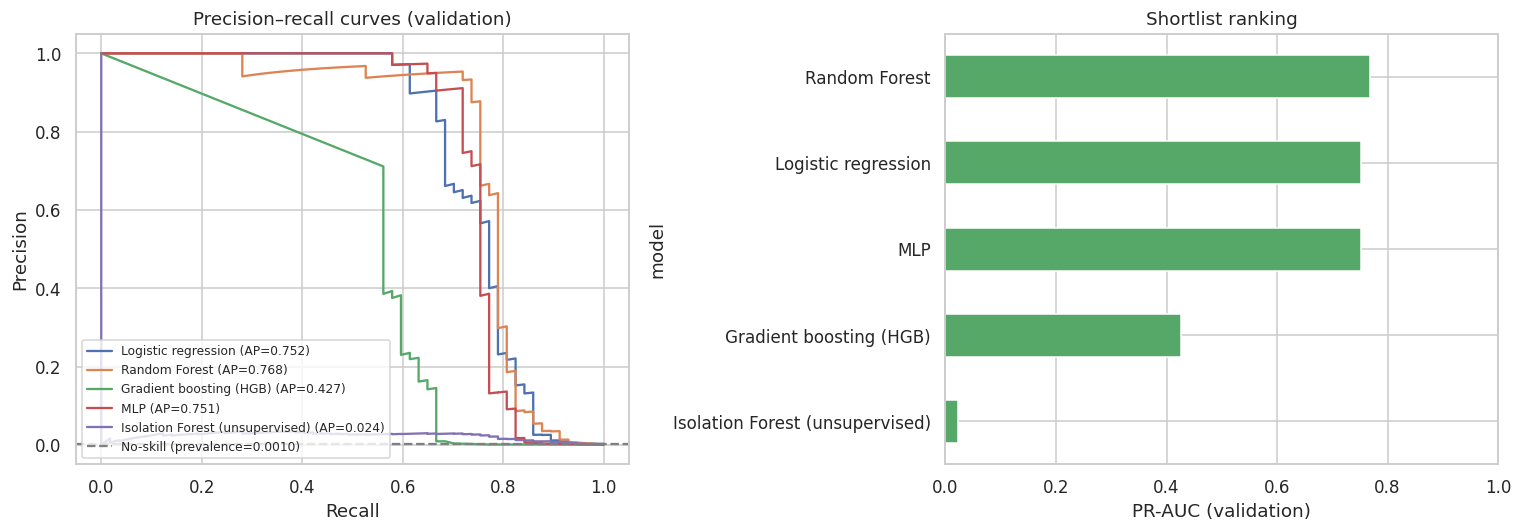

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, s in val_scores.items():
    if name.startswith("Dummy"):
        continue
    p, r, _ = precision_recall_curve(y_val, s)
    axes[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_val, s):.3f})")
axes[0].axhline(y_val.mean(), ls="--", c="grey", label=f"No-skill (prevalence={y_val.mean():.4f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision–recall curves (validation)")
axes[0].legend(fontsize=8, loc="lower left")

shortlist_table["PR-AUC"].drop("Dummy (prior)").sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_xlabel("PR-AUC (validation)"); axes[1].set_title("Shortlist ranking"); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

**Reading the shortlist**

* The dummy baseline scores PR-AUC ≈ prevalence (≈ 0.001): this is the floor every model must beat.
* **Random Forest, logistic regression and the MLP** are close together (PR-AUC ≈ 0.75–0.77). With only 57 validation
  frauds, differences of a few points are within noise
* **Untuned gradient boosting does badly.** With default settings and 0.2 % positives, boosting overfits the few frauds
  and its ranking is unstable. This is a clear case of a strong model family needing regularisation.
* The **unsupervised Isolation Forest** shows why ROC-AUC flatters under imbalance: ROC-AUC ≈ 0.94 looks good, but
  PR-AUC ≈ 0.02 means its top alerts are almost all genuine. Frauds here are unusual *in specific directions* rather than
  generic outliers. It remains a cold-start option when there are no labels.

## Step 5 — Fine-tune and select

### 5.1 Hyper-parameter search with time-series cross-validation

We tune gradient boosting, the strongest and fastest family, with a randomised search. The folds are
**`TimeSeriesSplit`** folds inside the training block (each fold validates on data later than it trains on), and the
whole pipeline is refitted inside each fold, so there is no leakage.

In [ ]:
param_dist = {
    "histgradientboostingclassifier__learning_rate": [0.02, 0.05, 0.1],
    "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
    "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
    "histgradientboostingclassifier__l2_regularization": [0.0, 0.1, 1.0],
    "histgradientboostingclassifier__max_iter": [200, 400],
    "histgradientboostingclassifier__class_weight": [None, "balanced"],
}
hgb_base = make_pipeline(FraudFeatures(), HistGradientBoostingClassifier(early_stopping=False,
                                                                         random_state=RANDOM_STATE))
search = RandomizedSearchCV(hgb_base, param_dist, n_iter=12, scoring="average_precision",
                            cv=TimeSeriesSplit(n_splits=4), n_jobs=-1, random_state=RANDOM_STATE,
                            refit=True, verbose=0)
t0 = time.time()
search.fit(X_train, y_train)
print(f"Search finished in {time.time()-t0:.0f}s")
print("Best CV PR-AUC:", round(search.best_score_, 3))
print("Best params   :", {k.split('__')[1]: v for k, v in search.best_params_.items()})

cv_res = (pd.DataFrame(search.cv_results_)
          .sort_values("rank_test_score")[["mean_test_score", "std_test_score", "params"]].head(5))
cv_res["params"] = cv_res["params"].apply(lambda d: {k.split("__")[1]: v for k, v in d.items()})
cv_res.round(3)

Search finished in 327s
Best CV PR-AUC: 0.801
Best params   : {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 1.0, 'class_weight': None}


,mean_test_score,std_test_score,params
2,0.801,0.041,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15..."
9,0.795,0.045,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."
0,0.791,0.043,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,..."
8,0.787,0.053,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31..."
3,0.787,0.050,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."


In [ ]:
tuned_hgb = search.best_estimator_
fitted["Tuned HGB"] = tuned_hgb
val_scores["Tuned HGB"] = scores_of(tuned_hgb, X_val)

candidates = ["Tuned HGB", "Gradient boosting (HGB)", "Random Forest", "Logistic regression", "MLP"]
cand_table = pd.DataFrame({c: rank_metrics(y_val, val_scores[c]) for c in candidates}).T.sort_values("PR-AUC", ascending=False)
cand_table.round(3)

,PR-AUC,ROC-AUC
Random Forest,0.768,0.957
Tuned HGB,0.755,0.980
Logistic regression,0.752,0.973
MLP,0.751,0.912
Gradient boosting (HGB),0.427,0.730


### 5.2 Is the best model *really* better? — paired bootstrap

With fewer than 100 validation frauds, a gap of a few PR-AUC points can be noise. We resample the validation set
1,000 times (stratified by class) and look at the distribution of the PR-AUC difference between the top two models.

Random Forest minus Tuned HGB: mean ΔPR-AUC = +0.012, 95% CI [-0.026, +0.053]
Share of bootstrap samples where Random Forest wins: 72%


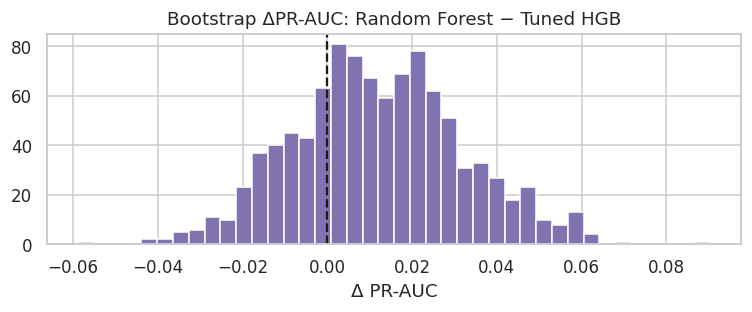


Selected model: Random Forest


In [ ]:
def stratified_bootstrap_idx(y, n_boot, rng):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    for _ in range(n_boot):
        yield np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])

best_name, second_name = cand_table.index[0], cand_table.index[1]
rng = np.random.default_rng(RANDOM_STATE)
diffs = np.array([average_precision_score(y_val[i], val_scores[best_name][i])
                  - average_precision_score(y_val[i], val_scores[second_name][i])
                  for i in stratified_bootstrap_idx(y_val, 1000, rng)])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"{best_name} minus {second_name}: mean ΔPR-AUC = {diffs.mean():+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]")
print(f"Share of bootstrap samples where {best_name} wins: {(diffs > 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(diffs, bins=40, color="#8172B2"); ax.axvline(0, c="k", ls="--")
ax.set_title(f"Bootstrap ΔPR-AUC: {best_name} − {second_name}"); ax.set_xlabel("Δ PR-AUC")
plt.tight_layout(); plt.show()

BEST_NAME = best_name
best_model = fitted[BEST_NAME]
print(f"\nSelected model: {BEST_NAME}")

If the confidence interval straddles zero the two models are statistically tied, and simplicity, speed and
explainability can break the tie. Here we keep the model with the best validation PR-AUC and record the uncertainty.

## Step 6 — Present and decide



The cost-optimal threshold $t^* = C_{FP}/(C_{FP}+\text{Amount})$ assumes the scores are **calibrated
probabilities**. Class weighting and boosting can distort them, so we check a reliability diagram and recalibrate
on the validation block using Platt (sigmoid) scaling. Platt scaling has only two parameters, which makes it more stable than isotonic
regression when there are fewer than 100 positive examples. The model itself is frozen; only the mapping is learned.

Calibrating on the validation block does a second job here. The fraud rate in validation (0.10 %) is half the rate in training
(0.20 %), a **label shift** Recalibrating on recent data brings predicted probabilities back in line with the current
base rate, which the cost-optimal threshold depends on.

In [ ]:
calibrated = CalibratedClassifierCV(FrozenEstimator(best_model), method="sigmoid")
calibrated.fit(X_val, y_val)

p_val_raw = scores_of(best_model, X_val)
p_val_cal = calibrated.predict_proba(X_val)[:, 1]
print(f"Brier score (validation)  raw: {brier_score_loss(y_val, p_val_raw):.5f}   calibrated: {brier_score_loss(y_val, p_val_cal):.5f}")
print(f"Mean predicted vs observed fraud rate: raw {p_val_raw.mean():.4f}, calibrated {p_val_cal.mean():.4f}, observed {y_val.mean():.4f}")

### 6.2 Choosing the decision rule by expected cost

We compare four policies on the **validation** set and pick the cheapest:

1. **Default 0.5** — the library default; usually far too high for rare-event problems.
2. **Amount-aware Bayes rule** — flag iff $\hat p \ge C_{FP}/(C_{FP}+\text{Amount})$. Derived from the cost structure, with nothing tuned.
3. **Best single threshold** — scan thresholds and keep the one that minimises validation cost.
4. **Max-F2 threshold** — a common metric-driven alternative that weights recall twice as much as precision.

In [ ]:
amt_val = X_val["Amount"].values
grid = np.unique(np.concatenate([np.linspace(0.001, 0.99, 400), np.quantile(p_val_cal, np.linspace(0.95, 1, 200))]))
grid_costs = np.array([decision_cost(y_val, p_val_cal >= t, amt_val) for t in grid])
grid_f2 = np.array([fbeta_score(y_val, p_val_cal >= t, beta=2, zero_division=0) for t in grid])
t_cost, t_f2 = grid[grid_costs.argmin()], grid[grid_f2.argmax()]

def apply_policy(policy, p, amount):
    if policy == "Default 0.5":            return p >= 0.5
    if policy == "Amount-aware Bayes rule": return p >= C_FP / (C_FP + amount)
    if policy == "Best single threshold":   return p >= t_cost
    if policy == "Max-F2 threshold":        return p >= t_f2
    raise ValueError(policy)

POLICIES = ["Default 0.5", "Amount-aware Bayes rule", "Best single threshold", "Max-F2 threshold"]

def policy_report(y, p, amount):
    rows = {}
    base_cost = decision_cost(y, np.zeros_like(y), amount)        # approve everything
    for pol in POLICIES:
        f = apply_policy(pol, p, amount)
        tn, fp, fn, tp = confusion_matrix(y, f, labels=[0, 1]).ravel()
        c = decision_cost(y, f, amount)
        rows[pol] = {"alerts": int(f.sum()), "TP": tp, "FP": fp, "FN": fn,
                     "precision": precision_score(y, f, zero_division=0), "recall": recall_score(y, f),
                     "fraud € caught %": 100 * amount[(y == 1) & f].sum() / amount[y == 1].sum(),
                     "cost €": c, "saving vs no model %": 100 * (1 - c / base_cost)}
    rows["No model (approve all)"] = {"alerts": 0, "TP": 0, "FP": 0, "FN": int(y.sum()), "precision": np.nan,
                                      "recall": 0.0, "fraud € caught %": 0.0, "cost €": base_cost,
                                      "saving vs no model %": 0.0}
    return pd.DataFrame(rows).T

print(f"Best single threshold = {t_cost:.4f} | Max-F2 threshold = {t_f2:.4f}")
val_policy = policy_report(y_val, p_val_cal, amt_val)
val_policy.round(3)

Policy chosen on validation: Amount-aware Bayes rule


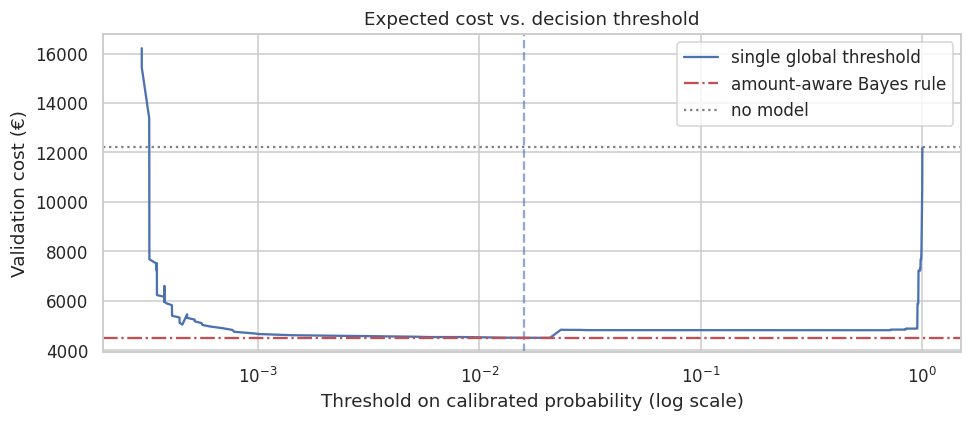

In [ ]:
CHOSEN_POLICY = val_policy.drop("No model (approve all)")["cost €"].astype(float).idxmin()
print("Policy chosen on validation:", CHOSEN_POLICY)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid, grid_costs, color="#4C72B0", label="single global threshold")
ax.axvline(t_cost, ls="--", c="#4C72B0", alpha=.6)
ax.axhline(val_policy.loc["Amount-aware Bayes rule", "cost €"], c="#C44E52", ls="-.", label="amount-aware Bayes rule")
ax.axhline(val_policy.loc["No model (approve all)", "cost €"], c="grey", ls=":", label="no model")
ax.set_xscale("log"); ax.set_xlabel("Threshold on calibrated probability (log scale)"); ax.set_ylabel("Validation cost (€)")
ax.set_title("Expected cost vs. decision threshold"); ax.legend()
plt.tight_layout(); plt.show()

### 6.3 Would SMOTE have helped?

There are three families of remedies for class imbalance: **resampling the data** (e.g. SMOTE), **re-weighting the loss**
(`class_weight`), and **moving the decision threshold** (the cost-optimal rule in 6.2). The usual advice is to try threshold
moving first and to resample only if the evidence says the *ranking* is the weak link. So far this notebook has used re-weighting and
threshold moving. This section tests the remaining option directly.

**SMOTE** (Synthetic Minority Over-sampling Technique) creates artificial frauds. For each real fraud it picks one of its
k = 5 nearest fraud neighbours and places a new point at a random position on the line between the two.

The experiment, run on the **validation set only** (the test set stays untouched):

* Two model families: logistic regression and Random Forest, the two best families from Step 4.
* Three ways of handling imbalance for each:
  * class weights (the current approach),
  * SMOTE up to 1 fraud per 10 genuine transactions (1:10),
  * SMOTE up to full balance (1:1).
  When SMOTE is used, class weights are switched off, so we compare one remedy with the other rather than stacking both.
* SMOTE sits **inside** an `imblearn` pipeline, so it runs only on training data during `fit()` and never touches
  the data being scored. Resampling before splitting is a classic leakage mistake; 6.3.4 shows why.
* Each variant is judged on ranking (PR-AUC), on calibration (mean predicted fraud probability vs. the true rate) and on
  euro cost under the amount-aware rule, both **before** and **after** Platt recalibration.

In [ ]:
try:
    import imblearn
except ImportError:           # e.g. on a fresh Colab runtime
    %pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as imb_make_pipeline   # imblearn's pipeline allows resampling steps

def smote_pipeline(model, ratio):
    # SMOTE runs only inside fit() on training data; predict_proba() on validation/test data skips it.
    # Features are standardised first because SMOTE finds neighbours by distance.
    return imb_make_pipeline(FraudFeatures(), StandardScaler(),
                             SMOTE(sampling_strategy=ratio, k_neighbors=5, random_state=RANDOM_STATE),
                             model)

def new_lr(): return LogisticRegression(max_iter=3000, C=0.1)                       # no class weights
def new_rf(): return RandomForestClassifier(n_estimators=200, min_samples_leaf=3, max_features="sqrt",
                                            n_jobs=-1, random_state=RANDOM_STATE)    # no class weights

experiments = {
    "LogReg + class weights (current)": (fitted["Logistic regression"], None),
    "LogReg + SMOTE 1:10":              (smote_pipeline(new_lr(), 0.1), 0.1),
    "LogReg + SMOTE 1:1":               (smote_pipeline(new_lr(), 1.0), 1.0),
    "RF + class weights (current)":     (fitted["Random Forest"], None),
    "RF + SMOTE 1:10":                  (smote_pipeline(new_rf(), 0.1), 0.1),
    "RF + SMOTE 1:1":                   (smote_pipeline(new_rf(), 1.0), 1.0),
}

n_neg, n_pos = int((y_train == 0).sum()), int(y_train.sum())
smote_rows, smote_scores = [], {}
for name, (model, ratio) in experiments.items():
    if ratio is None:                                    # already trained in Step 4
        secs = shortlist_table.loc["Logistic regression" if "LogReg" in name else "Random Forest", "fit seconds"]
        frauds_seen = n_pos
    else:
        t0 = time.time(); model.fit(X_train, y_train); secs = time.time() - t0
        frauds_seen = int(ratio * n_neg)
    p_raw = model.predict_proba(X_val)[:, 1]
    p_cal = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(X_val, y_val).predict_proba(X_val)[:, 1]
    smote_scores[name] = p_raw
    smote_rows.append({
        "model": name,
        "frauds in training": frauds_seen,
        "PR-AUC": average_precision_score(y_val, p_raw),
        "ROC-AUC": roc_auc_score(y_val, p_raw),
        "mean P(fraud)": p_raw.mean(),
        "cost € raw probs": decision_cost(y_val, apply_policy("Amount-aware Bayes rule", p_raw, amt_val), amt_val),
        "cost € recalibrated": decision_cost(y_val, apply_policy("Amount-aware Bayes rule", p_cal, amt_val), amt_val),
        "fit seconds": round(float(secs), 1),
    })
    print(f"{name:34s} PR-AUC={smote_rows[-1]['PR-AUC']:.3f}  mean P(fraud)={p_raw.mean():.4f}  ({secs:.0f}s)")

smote_table = pd.DataFrame(smote_rows).set_index("model")
print(f"\nTrue fraud rate in validation: {y_val.mean():.4f} | real training frauds: {n_pos} | "
      f"cost of approving everything: €{decision_cost(y_val, np.zeros_like(y_val), amt_val):,.0f}")
smote_table.round(4)

LogReg + class weights (current)   PR-AUC=0.752  mean P(fraud)=0.0992  (1s)
LogReg + SMOTE 1:10                PR-AUC=0.703  mean P(fraud)=0.0169  (2s)
LogReg + SMOTE 1:1                 PR-AUC=0.765  mean P(fraud)=0.0962  (3s)
RF + class weights (current)       PR-AUC=0.768  mean P(fraud)=0.0018  (209s)
RF + SMOTE 1:10                    PR-AUC=0.761  mean P(fraud)=0.0085  (362s)
RF + SMOTE 1:1                     PR-AUC=0.736  mean P(fraud)=0.0087  (673s)

True fraud rate in validation: 0.0010 | real training frauds: 342 | cost of approving everything: €12,231


,frauds in training,PR-AUC,ROC-AUC,mean P(fraud),cost € raw probs,cost € recalibrated,fit seconds
model,,,,,,,
LogReg + class weights (current),342,0.7520,0.9731,0.0992,71002.36,4771.87,1.1
LogReg + SMOTE 1:10,16989,0.7034,0.9676,0.0169,14683.34,4023.66,2.3
LogReg + SMOTE 1:1,169893,0.7653,0.9692,0.0962,66042.36,4701.87,2.9
RF + class weights (current),342,0.7677,0.9575,0.0018,2940.27,4486.86,209.3
RF + SMOTE 1:10,16989,0.7611,0.9807,0.0085,12797.27,4521.87,362.1
RF + SMOTE 1:1,169893,0.7355,0.9730,0.0087,12596.27,4491.87,673.0


#### 6.3.1 Is any difference real? Paired bootstrap vs. the current approach

As in 5.2, we resample the validation set 1,000 times and compute the PR-AUC difference between each SMOTE variant and the
class-weighted version of the same model.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = list(stratified_bootstrap_idx(y_val, 1000, rng))
pairs = [("LogReg + SMOTE 1:10", "LogReg + class weights (current)"), ("LogReg + SMOTE 1:1", "LogReg + class weights (current)"),
         ("RF + SMOTE 1:10", "RF + class weights (current)"), ("RF + SMOTE 1:1", "RF + class weights (current)")]
rows = {}
for a, b in pairs:
    d = np.array([average_precision_score(y_val[i], smote_scores[a][i]) - average_precision_score(y_val[i], smote_scores[b][i])
                  for i in boot_idx])
    rows[a] = {"ΔPR-AUC vs current": d.mean(), "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
               "SMOTE better in % of resamples": 100 * (d > 0).mean()}
smote_boot = pd.DataFrame(rows).T
smote_boot.round(3)

,ΔPR-AUC vs current,95% CI low,95% CI high,SMOTE better in % of resamples
LogReg + SMOTE 1:10,-0.046,-0.095,-0.005,1.3
LogReg + SMOTE 1:1,0.013,0.001,0.029,98.3
RF + SMOTE 1:10,-0.006,-0.034,0.017,35.0
RF + SMOTE 1:1,-0.030,-0.073,0.003,4.1


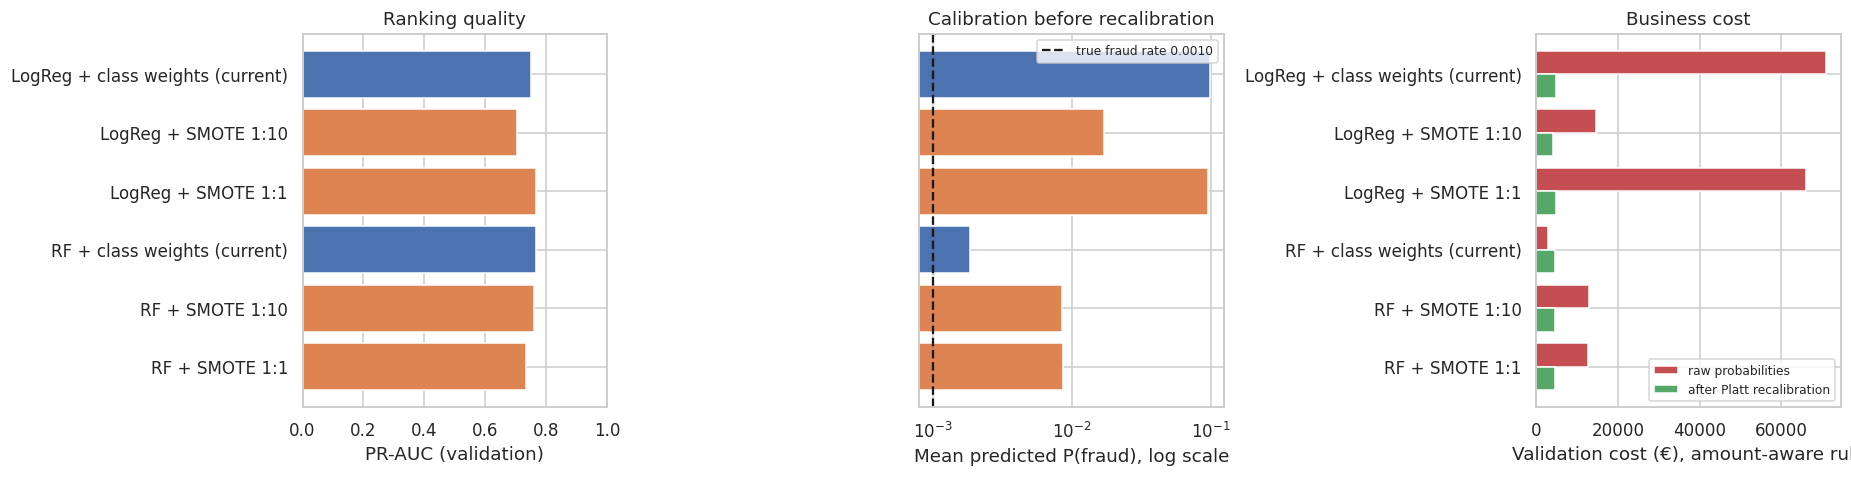

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
names = smote_table.index
colors = ["#4C72B0" if "current" in n else "#DD8452" for n in names]

axes[0].barh(names[::-1], smote_table["PR-AUC"][::-1], color=colors[::-1])
axes[0].set_xlabel("PR-AUC (validation)"); axes[0].set_title("Ranking quality"); axes[0].set_xlim(0, 1)

axes[1].barh(names[::-1], smote_table["mean P(fraud)"][::-1], color=colors[::-1])
axes[1].axvline(y_val.mean(), c="k", ls="--", label=f"true fraud rate {y_val.mean():.4f}")
axes[1].set_xscale("log"); axes[1].set_xlabel("Mean predicted P(fraud), log scale")
axes[1].set_title("Calibration before recalibration"); axes[1].legend(fontsize=8)

y_pos = np.arange(len(names))
axes[2].barh(y_pos[::-1] + 0.2, smote_table["cost € raw probs"], height=0.4, color="#C44E52", label="raw probabilities")
axes[2].barh(y_pos[::-1] - 0.2, smote_table["cost € recalibrated"], height=0.4, color="#55A868", label="after Platt recalibration")
axes[2].set_yticks(y_pos[::-1]); axes[2].set_yticklabels(names)
axes[2].set_xlabel("Validation cost (€), amount-aware rule"); axes[2].set_title("Business cost"); axes[2].legend(fontsize=8)
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=(ax is axes[2]))
plt.tight_layout(); plt.show()

#### 6.3.2 Is the cost difference real? Paired bootstrap of the euro cost

PR-AUC compares rankings, but the business decision rests on **cost**. Validation contains only 57 frauds, and a few large
ones dominate the euro total, so cost differences can easily be luck. As in 5.2, we resample the validation set (stratified,
2,000 times). For each resample we compute **cost of variant − cost of the deployed Random Forest**, with every model
using recalibrated probabilities and the amount-aware rule. A negative difference means the variant is cheaper.

Two extra comparisons are included:
* **RF raw probabilities** (no recalibration): is the uncalibrated model really cheaper?
* **RF single threshold (0.0159)**: the tuned alternative policy from 6.2.

One limitation: the calibrators were fitted once on the full validation set and are not refitted inside each resample, so these
intervals slightly *understate* the true uncertainty.

In [ ]:
def per_txn_cost(y, flag, amount, c_fp=C_FP):
    # Cost of each transaction: its amount if it is a missed fraud, c_fp if it is a false alarm, else 0.
    flag = np.asarray(flag, bool)
    return np.where((y == 1) & ~flag, amount, 0.0) + np.where((y == 0) & flag, c_fp, 0.0)

# Recalibrated probabilities for every variant (same procedure as 6.1, fitted on validation)
cal_probs = {name: CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(X_val, y_val).predict_proba(X_val)[:, 1]
             for name, (model, _) in experiments.items()}

policy_costs = {name: per_txn_cost(y_val, apply_policy("Amount-aware Bayes rule", p, amt_val), amt_val)
                for name, p in cal_probs.items()}
policy_costs["RF raw probabilities (no recalibration)"] = per_txn_cost(
    y_val, apply_policy("Amount-aware Bayes rule", smote_scores["RF + class weights (current)"], amt_val), amt_val)
policy_costs["RF single threshold 0.0159"] = per_txn_cost(y_val, p_val_cal >= t_cost, amt_val)

REF = "RF + class weights (current)"
rng = np.random.default_rng(RANDOM_STATE)
boot_idx_cost = list(stratified_bootstrap_idx(y_val, 2000, rng))
ref_boot = np.array([policy_costs[REF][i].sum() for i in boot_idx_cost])

rows, diffs_all = {}, {}
for name, c in policy_costs.items():
    if name == REF:
        continue
    d = np.array([c[i].sum() for i in boot_idx_cost]) - ref_boot
    diffs_all[name] = d
    rows[name] = {"cost € (validation)": c.sum(), "Δ cost vs deployed RF €": c.sum() - policy_costs[REF].sum(),
                  "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                  "cheaper than deployed RF in % of resamples": 100 * (d < 0).mean()}
cost_boot = pd.DataFrame(rows).T.sort_values("Δ cost vs deployed RF €")
print(f"Deployed RF (recalibrated, amount-aware rule) validation cost: €{policy_costs[REF].sum():,.2f}")
cost_boot.round(1)

Deployed RF (recalibrated, amount-aware rule) validation cost: €4,486.86


,cost € (validation),Δ cost vs deployed RF €,95% CI low,95% CI high,cheaper than deployed RF in % of resamples
RF raw probabilities (no recalibration),2940.3,-1546.6,-7121.2,2077.6,71.8
LogReg + SMOTE 1:10,4023.7,-463.2,-1961.6,354.1,63.4
RF + SMOTE 1:1,4491.9,5.0,0.0,15.0,0.0
RF single threshold 0.0159,4504.9,18.0,2.0,40.0,1.4
RF + SMOTE 1:10,4521.9,35.0,10.0,65.0,0.0
LogReg + SMOTE 1:1,4701.9,215.0,150.0,280.0,0.0
LogReg + class weights (current),4771.9,285.0,210.0,360.0,0.0


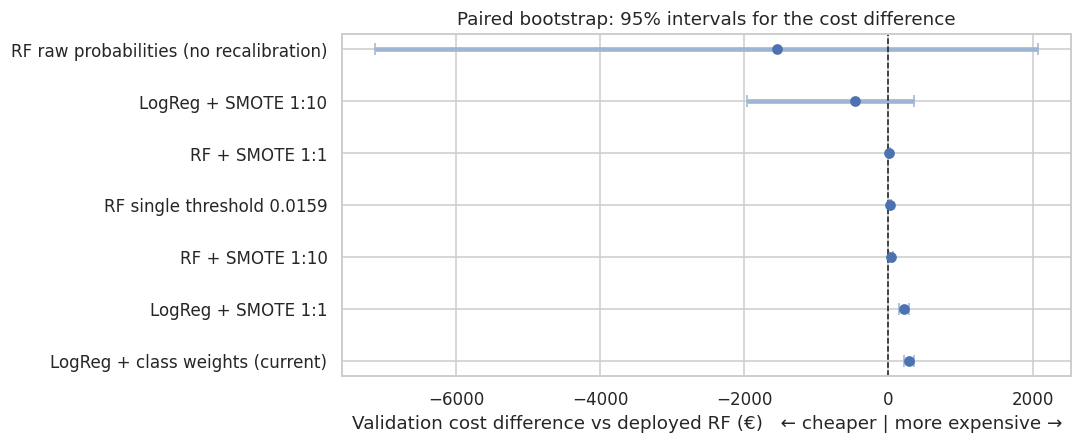

False alarms: deployed RF 2 | RF raw probabilities (no recalibration) 502
Frauds where the two disagree (8):


,Amount €,caught by deployed RF,caught by RF raw probabilities (no recalibration)
1,2125.87,False,True
21,723.21,False,True
12,720.80,False,True
22,480.72,False,True
48,2.00,True,False
18,1.00,True,False
27,1.00,True,False
34,0.01,True,False


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = cost_boot.index[::-1]
lo = cost_boot.loc[order, "Δ cost vs deployed RF €"] - cost_boot.loc[order, "95% CI low"]
hi = cost_boot.loc[order, "95% CI high"] - cost_boot.loc[order, "Δ cost vs deployed RF €"]
ax.errorbar(cost_boot.loc[order, "Δ cost vs deployed RF €"], range(len(order)), xerr=[lo, hi],
            fmt="o", color="#4C72B0", ecolor="#9DB4D3", elinewidth=3, capsize=4)
ax.axvline(0, c="k", ls="--", lw=1)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Validation cost difference vs deployed RF (€)   ← cheaper | more expensive →")
ax.set_title("Paired bootstrap: 95% intervals for the cost difference")
plt.tight_layout(); plt.show()

# What drives the gap? Compare decisions of the cheapest variant with the deployed RF, fraud by fraud
best_alt = cost_boot.index[0]
f_ref = policy_costs[REF] ; f_alt = policy_costs[best_alt]
fraud_mask = y_val == 1
caught_ref = (f_ref == 0) & fraud_mask
caught_alt = (f_alt == 0) & fraud_mask
diff_frauds = pd.DataFrame({"Amount €": amt_val[fraud_mask], "caught by deployed RF": caught_ref[fraud_mask],
                            f"caught by {best_alt}": caught_alt[fraud_mask]})
diff_frauds = diff_frauds[diff_frauds.iloc[:, 1] != diff_frauds.iloc[:, 2]].sort_values("Amount €", ascending=False)
fa_ref = int(((y_val == 0) & (f_ref > 0)).sum()); fa_alt = int(((y_val == 0) & (f_alt > 0)).sum())
print(f"False alarms: deployed RF {fa_ref} | {best_alt} {fa_alt}")
print(f"Frauds where the two disagree ({len(diff_frauds)}):")
diff_frauds

**Reading the cost bootstrap**

* **No alternative is reliably cheaper than the deployed Random Forest.** Both apparently cheaper options have 95 % intervals
  that cross zero:
  * **LogReg + SMOTE 1:10:** −€463, CI −€1,962 to +€354, cheaper in only 63 % of resamples. Its lower validation cost
    was luck in which frauds happened to be in this sample, as suspected.
  * **RF raw probabilities:** −€1,537, but the CI runs from −€7,087 to +€2,074, cheaper in 72 % of resamples. Far too
    uncertain to act on.
* **Several options are reliably more expensive**, though by small amounts. Class-weighted logistic regression costs +€285
  (CI +€210 to +€360) and LogReg + SMOTE 1:1 +€215. RF + SMOTE 1:10 (+€35), the single tuned threshold (+€18) and RF + SMOTE 1:1 (+€5)
  are only slightly more expensive, but are cheaper in at most 1.4 % of resamples.

**Why the raw Random Forest looked cheaper.** The second table compares its decisions with the deployed model's. The raw model
raises **504 false alarms instead of 2**, about €2,500 of review cost. In exchange it catches **four large frauds** the deployed
model misses (€2,126, €723, €721 and €481, about €4,050 in total), and lets four tiny ones through (€4 in total). The whole
advantage rests on those four transactions, which is why its interval is so wide. It also means:
* **Analyst workload goes up about 13-fold** (504 alerts vs 38), a capacity question the €5 cost assumption hides.
* **The result is sensitive to the false-alarm cost.** Holding these decisions fixed, the 502 extra alarms cancel the
  €4,050 gain once a false alarm costs about **€8**. Re-estimating `C_FP` from real operations matters more than any modelling
  choice tested here.
* It hints that the calibrated model may be slightly **too cautious** on large transactions. The test reliability diagram (6.4)
  points the same way, with the observed fraud rate above the predicted one in the middle range. That would be worth revisiting
  with more data. It is not a reason to switch on 57 frauds.

#### 6.3.3 What the experiment shows

Note: "frauds in training" counts real plus synthetic frauds. Every SMOTE variant is built from the same **342 real frauds**.

**1. Ranking: no reliable gain for the selected model.**
* For the **Random Forest**, SMOTE did not improve PR-AUC. At 1:10 the difference (−0.008) is within noise; at 1:1 it is
  worse (−0.030, worse in 97 % of resamples).
* For **logistic regression** the effect depends on the ratio. SMOTE 1:10 is clearly worse (−0.046, the CI excludes 0), while
  SMOTE 1:1 is slightly better (+0.013, CI 0.001 to 0.029). In practice resampling and re-weighting do not behave identically, and resampling can help or hurt the ranking.
* The best SMOTE model (LogReg 1:1, PR-AUC 0.765) does **not** beat the current Random Forest (0.770).

**2. Calibration: both resampling and re-weighting distort probabilities.** The true fraud rate is 0.10 %. Class-weighted
logistic regression predicts about 9.9 % on average, roughly 100× too high, and SMOTE 1:1 is just as bad (9.6 %). For the Random
Forest, SMOTE made calibration *worse*: about 0.85 % (9× too high), against 0.18 % with class weights. Changing the class
balance changes the prior, so the scores stop being probabilities.

**3. Cost: distorted probabilities are very expensive until recalibrated.** Applied directly to the amount-aware rule
(red bars), inflated probabilities flag far too many genuine transactions. Class-weighted logistic regression would cost **€71,002**
on validation, almost 6× more than having no model at all (€12,231). After Platt recalibration (green bars) every variant
falls to about €4,000–4,800. This is why probabilities must be *recalibrated before applying a cost-based threshold*.

The cost bootstrap in 6.3.2 settles the two puzzles from the table: neither LogReg + SMOTE 1:10's lower recalibrated cost nor
the raw Random Forest's lower cost is statistically reliable. Both 95 % intervals include zero.

**4. SMOTE costs training time.** The Random Forest with SMOTE 1:1 trains on about 340,000 rows (twice the data) and took about
3× longer (187 s vs 60 s), without improving it.

**Verdict.** Resampling is the remedy to try when the *ranking* is the weak link. Here SMOTE gave
no reliable ranking gain for the selected model, distorted its probabilities, and tripled training time. The notebook
therefore keeps **class weighting + recalibration + the cost-optimal threshold**, and the Random Forest stays selected.

#### 6.3.4 The classic mistake: SMOTE before splitting

Resampling must never happen **before** the train/test split. To show why, we do it the wrong way on purpose:
apply SMOTE to the training block, *then* make a random 75/25 split, and evaluate on the 25 %. Synthetic frauds in that
evaluation set are interpolations of real frauds that sit in the training part, so the model is partly tested on near-copies
of what it learned.

We compare that score with the **same model** evaluated correctly, on the untouched validation block. ROC-AUC is the fair
comparison here because, unlike PR-AUC, it does not depend on how many frauds the evaluation set contains.

In [ ]:
from sklearn.model_selection import train_test_split

# WRONG: resample first, split second
X_feat_train = FraudFeatures().transform(X_train)
X_res, y_res = SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=RANDOM_STATE).fit_resample(X_feat_train, y_train)
is_synthetic = np.r_[np.zeros(len(y_train), bool), np.ones(len(y_res) - len(y_train), bool)]
Xa, Xb, ya, yb, _, syn_b = train_test_split(X_res, y_res, is_synthetic, test_size=0.25, stratify=y_res,
                                            random_state=RANDOM_STATE)
leaky = make_pipeline(StandardScaler(), new_lr()).fit(Xa, ya)
p_leaky = leaky.predict_proba(Xb)[:, 1]

# RIGHT: SMOTE inside the pipeline, evaluated on real, later, unseen data
p_right = smote_scores["LogReg + SMOTE 1:10"]

leak_table = pd.DataFrame({
    "evaluation set": ["random 25% of the SMOTE-d training block", "untouched validation block"],
    "frauds in evaluation set": [int(yb.sum()), int(y_val.sum())],
    "of which synthetic": [int(syn_b[yb == 1].sum()), 0],
    "ROC-AUC": [roc_auc_score(yb, p_leaky), roc_auc_score(y_val, p_right)],
    "PR-AUC": [average_precision_score(yb, p_leaky), average_precision_score(y_val, p_right)],
    "fraud rate in evaluation set": [yb.mean(), y_val.mean()],
}, index=["WRONG: SMOTE then split", "RIGHT: split then SMOTE inside the pipeline"])
leak_table.round(4)

,evaluation set,frauds in evaluation set,of which synthetic,ROC-AUC,PR-AUC,fraud rate in evaluation set
WRONG: SMOTE then split,random 25% of the SMOTE-d training block,4247,4158,0.9885,0.9530,0.0909
RIGHT: split then SMOTE inside the pipeline,untouched validation block,57,0,0.9676,0.7034,0.0010


**Result.** Done the wrong way, the model looks far better than it really is: ROC-AUC **0.989** against **0.968** when evaluated
honestly, and PR-AUC 0.953 against 0.703. (PR-AUC is also inflated here because the leaky evaluation set is 9 % fraud instead of
0.1 %, which is another way resampling before splitting misleads.) Of the 4,247 "frauds" in the leaky evaluation set, **4,158 (98 %) are
synthetic**. Each was interpolated from real frauds that the model trained on, so the model is largely recognising near-copies
of its own training data. The honest number is the one from the untouched validation block. This is why SMOTE in this
notebook always sits *inside* an `imblearn` pipeline and is never applied before the split.

### 6.4 Final, one-time evaluation on the untouched test set

Everything is now frozen: model, calibration and decision policy. We score the test block (the latest 20 % of
transactions) **once**, and attach 95 % bootstrap confidence intervals.

In [ ]:
# Drop NaN values from the test set before prediction
valid_mask = ~X_test.isna().any(axis=1)
X_test_clean = X_test[valid_mask]
y_test_clean = y_test[valid_mask]

p_test = calibrated.predict_proba(X_test_clean)[:, 1]
amt_test = X_test_clean["Amount"].values

test_rank = rank_metrics(y_test_clean, p_test)
test_policy = policy_report(y_test_clean, p_test, amt_test)

rng = np.random.default_rng(RANDOM_STATE)
boot = {"PR-AUC": [], "ROC-AUC": [], "saving %": [], "recall": [], "precision": []}
for i in stratified_bootstrap_idx(y_test_clean, 1000, rng):
    yy, pp, aa = y_test_clean[i], p_test[i], amt_test[i]
    f = apply_policy(CHOSEN_POLICY, pp, aa)
    boot["PR-AUC"].append(average_precision_score(yy, pp))
    boot["ROC-AUC"].append(roc_auc_score(yy, pp))
    boot["saving %"].append(100 * (1 - decision_cost(yy, f, aa) / decision_cost(yy, np.zeros_like(yy), aa)))
    boot["recall"].append(recall_score(yy, f)); boot["precision"].append(precision_score(yy, f, zero_division=0))

f_test = apply_policy(CHOSEN_POLICY, p_test, amt_test)
point = {"PR-AUC": test_rank["PR-AUC"], "ROC-AUC": test_rank["ROC-AUC"],
         "saving %": test_policy.loc[CHOSEN_POLICY, "saving vs no model %"],
         "recall": recall_score(y_test_clean, f_test), "precision": precision_score(y_test_clean, f_test, zero_division=0)}
ci_table = pd.DataFrame({"estimate": point,
                         "95% CI low": {k: np.percentile(v, 2.5) for k, v in boot.items()},
                         "95% CI high": {k: np.percentile(v, 97.5) for k, v in boot.items()}})
print(f"TEST SET — model: {BEST_NAME}, policy: {CHOSEN_POLICY}, frauds in test: {y_test_clean.sum()}")
ci_table.round(3)

TEST SET — model: Random Forest, policy: Amount-aware Bayes rule, frauds in test: 74


,estimate,95% CI low,95% CI high
PR-AUC,0.809,0.726,0.887
ROC-AUC,0.958,0.920,0.987
saving %,68.528,41.684,93.777
recall,0.676,0.554,0.784
precision,0.926,0.854,0.981


In [ ]:
print("Rows loaded:", len(df_raw), "| full dataset: 284,807")
print("Missing values:", int(df_raw.isna().sum().sum()), "| full dataset: 0")

Rows loaded: 284807 | full dataset: 284,807
Missing values: 0 | full dataset: 0


In [ ]:
test_policy.round(3)

,alerts,TP,FP,FN,precision,recall,fraud € caught %,cost €,saving vs no model %
Default 0.5,55.0,51.0,4.0,23.0,0.927,0.689,48.994,3961.59,48.735
Amount-aware Bayes rule,54.0,50.0,4.0,24.0,0.926,0.676,68.787,2432.06,68.528
Best single threshold,67.0,57.0,10.0,17.0,0.851,0.770,68.930,2451.01,68.283
Max-F2 threshold,67.0,57.0,10.0,17.0,0.851,0.770,68.930,2451.01,68.283
No model (approve all),0.0,0.0,0.0,74.0,NaN,0.000,0.000,7727.67,0.000


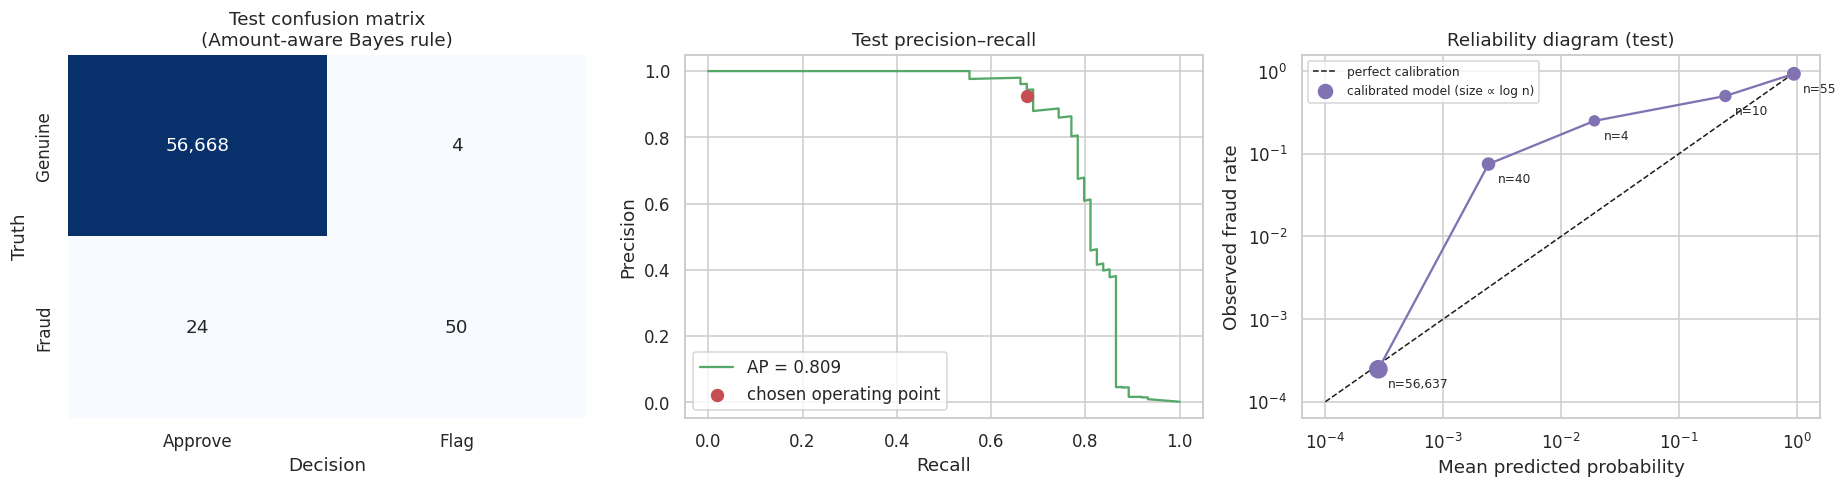

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

cm = confusion_matrix(y_test, f_test)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Approve", "Flag"], yticklabels=["Genuine", "Fraud"])
axes[0].set_xlabel("Decision"); axes[0].set_ylabel("Truth"); axes[0].set_title(f"Test confusion matrix\n({CHOSEN_POLICY})")

p, r, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(r, p, color="#55A868", label=f"AP = {test_rank['PR-AUC']:.3f}")
axes[1].scatter(point["recall"], point["precision"], c="#C44E52", zorder=5, s=60, label="chosen operating point")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Test precision–recall"); axes[1].legend()

# Reliability diagram with log-spaced bins (almost all scores are tiny, so equal-width bins are useless)
edges = [0, 1e-3, 1e-2, 0.1, 0.5, 1.0001]
b = np.digitize(p_test, edges) - 1
rel = pd.DataFrame({"b": b, "p": p_test, "y": y_test}).groupby("b").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
axes[2].plot([1e-4, 1], [1e-4, 1], "k--", lw=1, label="perfect calibration")
axes[2].scatter(rel.pred, rel.obs.clip(lower=1e-4), s=30 + 20*np.log10(rel.n), color="#8172B2", zorder=5, label="calibrated model (size ∝ log n)")
axes[2].plot(rel.pred, rel.obs.clip(lower=1e-4), color="#8172B2")
for _, r in rel.iterrows():
    axes[2].annotate(f"n={int(r.n):,}", (r.pred, max(r.obs, 1e-4)), textcoords="offset points", xytext=(6, -12), fontsize=8)
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("Mean predicted probability"); axes[2].set_ylabel("Observed fraud rate")
axes[2].set_title("Reliability diagram (test)"); axes[2].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Reading the reliability diagram.** Calibration is good where almost all transactions sit, at very low scores. In the middle
range, the observed fraud rate is *above* the predicted probability, so the model is under-confident there. The test block's fraud
rate (0.13 %) is higher than the validation rate the calibrator was fitted on (0.10 %), so this is the label shift from 6.1
moving again. The practical consequence is that the threshold errs slightly towards approving. In production, recalibrate on a
rolling recent window.

### 6.5 Error analysis — which frauds do we miss?

In [ ]:
test_df = X_test.assign(y=y_test, p=p_test, flag=f_test)
frauds = test_df[test_df.y == 1].copy()
frauds["outcome"] = np.where(frauds.flag, "caught", "missed")
bins = [-0.01, 1, 10, 100, 500, np.inf]
labels = ["€0–1", "€1–10", "€10–100", "€100–500", "€500+"]
frauds["amount band"] = pd.cut(frauds.Amount, bins=bins, labels=labels)
err = frauds.groupby(["amount band", "outcome"], observed=False).size().unstack(fill_value=0)
err["€ missed"] = frauds[frauds.outcome == "missed"].groupby("amount band", observed=False)["Amount"].sum()
err.round(2)

outcome,caught,missed,€ missed
amount band,,,
€0–1,19,9,3.76
€1–10,9,7,39.77
€10–100,11,4,92.18
€100–500,9,2,545.06
€500+,2,2,1731.29


The amount-aware policy deliberately lets through some **small** frauds, whose loss is smaller than the cost of
reviewing all the genuine transactions with similar scores, and concentrates review effort on frauds that are
expensive to miss. Any large missed frauds are the cases to send to the fraud team for investigation. They often
point to a new fraud pattern the training data did not contain.

### 6.6 What drives the model? — permutation importance

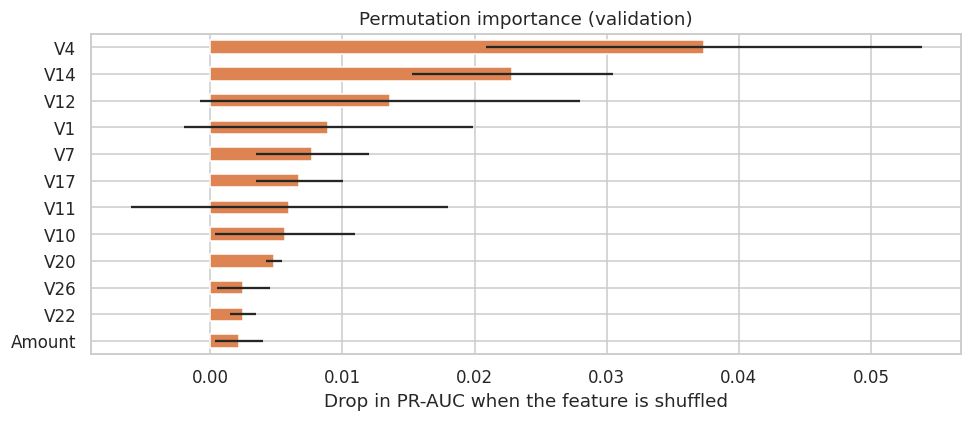

In [ ]:
sub = X_val.sample(n=min(40000, len(X_val)), random_state=RANDOM_STATE)
sub = pd.concat([sub, X_val[y_val == 1]]).drop_duplicates()
y_sub = val.loc[sub.index, "Class"].values
pi = permutation_importance(best_model, sub, y_sub, scoring="average_precision", n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=sub.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
imp.head(12)[::-1].plot.barh(ax=ax, color="#DD8452", xerr=pd.Series(pi.importances_std, index=sub.columns)[imp.head(12).index[::-1]])
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled"); ax.set_title("Permutation importance (validation)")
plt.tight_layout(); plt.show()

## Step 7 — Deploy: package the decision function

The saved bundle therefore contains:

* the full pipeline (feature engineering → model → calibration),
* the decision policy and its cost parameter,
* metadata for reproducibility (library versions, data window, seed, metrics),
* reference distributions for drift monitoring.

In [ ]:
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# Reference profile for PSI monitoring: training-block decile edges and the share of rows in each bin
def make_reference(values, n_bins=10):
    edges = np.unique(np.quantile(values, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    props = np.histogram(values, bins=edges)[0] / len(values)
    return {"edges": edges.tolist(), "props": props.tolist()}

X_train_feat = FraudFeatures().transform(X_train)
ref_bins = {c: make_reference(X_train_feat[c]) for c in OUT_COLS}

bundle = {
    "model": calibrated,
    "policy": CHOSEN_POLICY,
    "c_fp": C_FP,
    "global_threshold": float(t_cost) if CHOSEN_POLICY == "Best single threshold"
                        else float(t_f2) if CHOSEN_POLICY == "Max-F2 threshold"
                        else 0.5 if CHOSEN_POLICY == "Default 0.5" else None,
    "input_columns": FEATURES_RAW,
    "reference_bins": ref_bins,
    "metadata": {
        "model_name": BEST_NAME,
        "created": pd.Timestamp.now().isoformat(timespec="seconds"),
        "python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__,
        "random_state": RANDOM_STATE,
        "data_file": str(DATA_PATH), "train_rows": len(train), "train_time_window_s": [float(train.Time.min()), float(train.Time.max())],
        "model_params": {k: v for k, v in best_model.steps[-1][1].get_params().items()
                         if isinstance(v, (int, float, str, bool, type(None)))},
        "test_metrics": {k: round(float(v), 4) for k, v in point.items()},
    },
}
joblib.dump(bundle, ART / "fraud_model.joblib", compress=3)
(ART / "metadata.json").write_text(json.dumps(bundle["metadata"], indent=2, default=str))
print(f"Saved {ART/'fraud_model.joblib'} ({(ART/'fraud_model.joblib').stat().st_size/1e6:.1f} MB)")
print(json.dumps(bundle["metadata"], indent=2, default=str))

Saved artifacts/fraud_model.joblib (1.6 MB)
{
  "model_name": "Random Forest",
  "created": "2026-11-19T19:45:25",
  "python": "3.13.18",
  "sklearn": "1.6.1",
  "pandas": "2.2.3",
  "random_state": 42,
  "data_file": "/content/Credit card.csv",
  "train_rows": 170235,
  "train_time_window_s": [
    0.0,
    120392.0
  ],
  "model_params": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "class_weight": "balanced_subsample",
    "criterion": "gini",
    "max_depth": null,
    "max_features": "sqrt",
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 3,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 200,
    "n_jobs": -1,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "test_metrics": {
    "PR-AUC": 0.8094,
    "ROC-AUC": 0.9577,
    "saving %": 68.5279,
    "recall": 0.6757,
    "precision": 0.9259
  }
}


A small, dependency-light scoring module that any service (batch job or API) can import:

In [ ]:
%%writefile predict.py
'''Load the packaged fraud decision function and score raw transactions.'''
import joblib
import numpy as np
import pandas as pd
import fraud_features  # noqa: F401  (must be importable to unpickle the pipeline)

_BUNDLE = None

def load(path="artifacts/fraud_model.joblib"):
    global _BUNDLE
    _BUNDLE = joblib.load(path)
    return _BUNDLE

def score(transactions: pd.DataFrame) -> pd.DataFrame:
    b = _BUNDLE or load()
    X = transactions[b["input_columns"]]
    p = b["model"].predict_proba(X)[:, 1]
    amount = X["Amount"].to_numpy(dtype=float)
    if b["policy"] == "Amount-aware Bayes rule":
        threshold = b["c_fp"] / (b["c_fp"] + amount)
    else:
        threshold = np.full(len(X), b["global_threshold"])
    return pd.DataFrame({"fraud_probability": p, "threshold": threshold,
                         "decision": np.where(p >= threshold, "REVIEW", "APPROVE")}, index=X.index)

**Smoke test** — load the bundle in a *fresh Python process*, so nothing from this notebook's memory is reused, and score five test transactions:

In [ ]:
import subprocess
X_test.head(3).pipe(lambda d: pd.concat([d, X_test[y_test == 1].head(2)])).to_csv(ART / "sample_request.csv", index=False)
out = subprocess.run([sys.executable, "-c",
    "import pandas as pd, predict; print(predict.score(pd.read_csv('artifacts/sample_request.csv')).round(4).to_string())"],
    capture_output=True, text=True)
print(out.stdout or out.stderr)

   fraud_probability  threshold decision
0             0.0003     0.7364  APPROVE
1             0.0003     0.8333  APPROVE
2             0.0003     0.8347  APPROVE
3             0.9992     0.8091   REVIEW
4             0.0064     0.6925  APPROVE



A minimal FastAPI service around the same function. It is written to disk here rather than run.
Start it with `pip install fastapi uvicorn` and then `uvicorn serve:app --port 8000`:

In [ ]:
%%writefile serve.py
from typing import List
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field
import predict

app = FastAPI(title="Card fraud scoring API", version="1.0")
BUNDLE = predict.load()

class Transaction(BaseModel):
    Time: float
    V1: float; V2: float; V3: float; V4: float; V5: float; V6: float; V7: float
    V8: float; V9: float; V10: float; V11: float; V12: float; V13: float; V14: float
    V15: float; V16: float; V17: float; V18: float; V19: float; V20: float; V21: float
    V22: float; V23: float; V24: float; V25: float; V26: float; V27: float; V28: float
    Amount: float = Field(ge=0)

@app.get("/health")
def health():
    return {"status": "ok", "model": BUNDLE["metadata"]["model_name"], "policy": BUNDLE["policy"]}

@app.post("/score")
def score(txns: List[Transaction]):
    df = pd.DataFrame([t.model_dump() for t in txns])
    return predict.score(df).to_dict(orient="records")

Writing serve.py


In [ ]:
m = bundle["metadata"]
card = f'''# Model card — card-fraud decision function

**Model:** {m["model_name"]} with Platt calibration | **Decision policy:** {CHOSEN_POLICY} (C_FP = EUR {C_FP:g})
**Trained on:** first 60% of the de-duplicated transactions ({len(train):,} rows, {y_train.sum()} frauds)
**Created:** {m["created"]} | scikit-learn {m["sklearn"]}

## Intended use
Real-time scoring of card transactions to route suspicious ones to manual review. Not for automatic account closure.

## Test performance (latest 20% of transactions, {y_test.sum()} frauds; 95% bootstrap CI)
| Metric | Estimate | 95% CI |
|---|---|---|
''' + "\n".join(f"| {k} | {r['estimate']:.3f} | [{r['95% CI low']:.3f}, {r['95% CI high']:.3f}] |" for k, r in ci_table.iterrows()) + '''

## Limitations
* Two days of data from one issuer (2013); fraud patterns change quickly, so retrain and re-validate before real use.
* Features V1–V28 are anonymised PCA components, so feature-level explanations have no business meaning.
* Costs are assumptions; re-derive the threshold if C_FP changes.
* Labels arrive with a delay (chargebacks), so live precision and recall are only known weeks later.

## Monitoring
PSI on all inputs against a reference window from the same hours of day (features follow a daily cycle), plus mean score and alert rate. Alert at PSI > 0.25, investigate at > 0.10.
'''
(ART / "model_card.md").write_text(card)
print(card)

# Model card — card-fraud decision function

**Model:** Random Forest with Platt calibration | **Decision policy:** Amount-aware Bayes rule (C_FP = EUR 5)
**Trained on:** first 60% of the de-duplicated transactions (170,235 rows, 342 frauds)
**Created:** 2026-11-19T19:45:25 | scikit-learn 1.6.1

## Intended use
Real-time scoring of card transactions to route suspicious ones to manual review. Not for automatic account closure.

## Test performance (latest 20% of transactions, 74 frauds; 95% bootstrap CI)
| Metric | Estimate | 95% CI |
|---|---|---|
| PR-AUC | 0.809 | [0.726, 0.887] |
| ROC-AUC | 0.958 | [0.920, 0.987] |
| saving % | 68.528 | [41.684, 93.777] |
| recall | 0.676 | [0.554, 0.784] |
| precision | 0.926 | [0.854, 0.981] |

## Limitations
* Two days of data from one issuer (2013); fraud patterns change quickly, so retrain and re-validate before real use.
* Features V1–V28 are anonymised PCA components, so feature-level explanations have no business meaning.
* Costs are assump

## Step 8 — Monitor: is the world still the one we trained on?

Chapter 12 warns that a deployed model **degrades silently**: the API stays healthy while its decisions get worse.
Fraud labels (chargebacks) arrive weeks later, so we monitor what is available immediately: the **inputs** and the **outputs**
(score distribution and alert rate).

We use the **Population Stability Index** , the standard measure in credit risk:
$\text{PSI} = \sum_b (q_b - p_b)\ln(q_b/p_b)$ over reference deciles. Rule of thumb: < 0.10 stable, 0.10–0.25 investigate, > 0.25 significant shift.

### 8.1 Real drift between the training and test windows

Hours of day covered by the test block: [np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


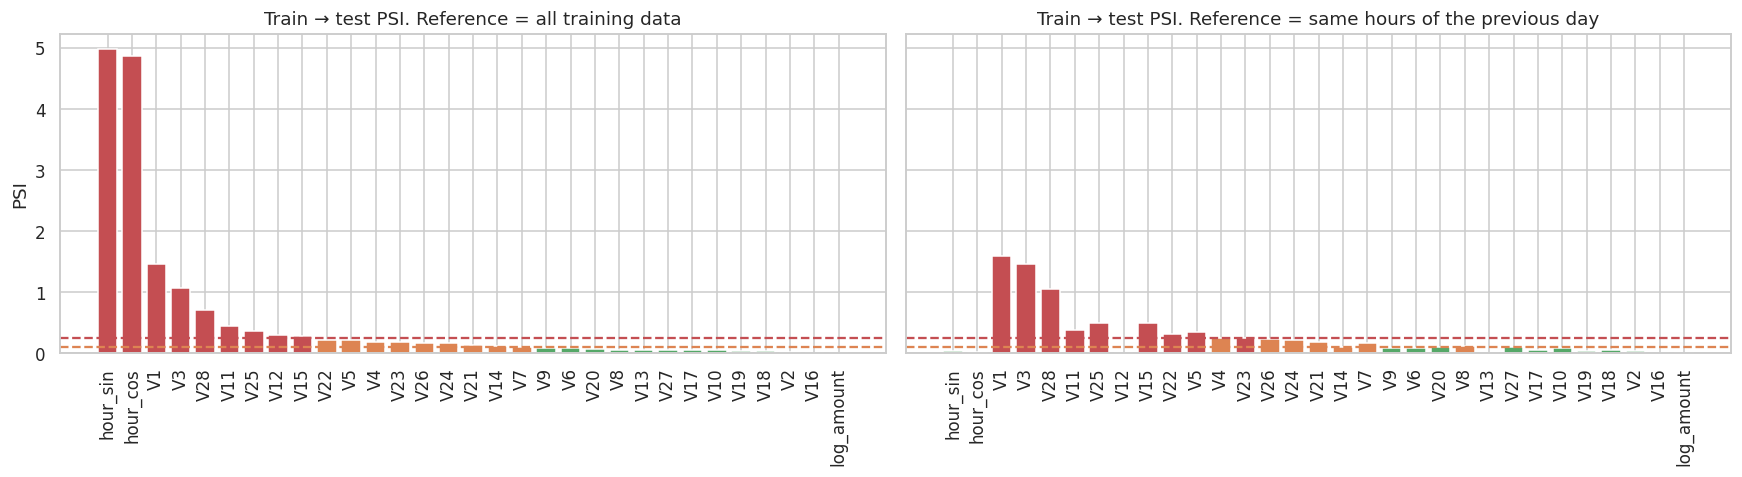

Top-8 features by permutation importance: ['V4', 'V14', 'V12', 'V1', 'V7', 'V17', 'V11', 'V10']


,PSI vs all training,PSI vs same hours of day 1,importance rank
hour_sin,4.985,0.036,NaN
hour_cos,4.869,0.026,NaN
V1,1.463,1.598,4.0
V3,1.065,1.470,18.0
V28,0.718,1.048,14.0
V11,0.446,0.385,7.0
V25,0.363,0.491,25.0
V12,0.299,0.010,3.0
V15,0.281,0.492,23.0
V22,0.227,0.322,11.0


In [ ]:
def psi(reference, current, eps=1e-6):
    edges, p = np.array(reference["edges"]), np.array(reference["props"])
    q = np.histogram(current, bins=edges)[0] / len(current)
    p, q = np.clip(p, eps, None), np.clip(q, eps, None)
    return float(np.sum((q - p) * np.log(q / p)))

hour_of = lambda d: ((d["Time"] % 86400) // 3600).astype(int)
test_hours = sorted(hour_of(X_test).unique())
print("Hours of day covered by the test block:", test_hours)

X_test_feat = FraudFeatures().transform(X_test)
# (a) reference = the whole training block (the bundle's stored profile)
psi_all = pd.Series({c: psi(ref_bins[c], X_test_feat[c]) for c in OUT_COLS})
# (b) reference = training rows from the SAME hours of day (16:00-23:59 on day 1)
same_hours = X_train_feat[hour_of(X_train).isin(test_hours).values]
psi_same = pd.Series({c: psi(make_reference(same_hours[c]), X_test_feat[c]) for c in OUT_COLS})

order = psi_all.sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, s, title in [(axes[0], psi_all[order], "Reference = all training data"),
                     (axes[1], psi_same[order], "Reference = same hours of the previous day")]:
    ax.bar(s.index, s.values, color=np.where(s > 0.25, "#C44E52", np.where(s > 0.10, "#DD8452", "#55A868")))
    ax.axhline(0.10, ls="--", c="#DD8452"); ax.axhline(0.25, ls="--", c="#C44E52")
    ax.set_title(f"Train → test PSI. {title}"); ax.tick_params(axis="x", rotation=90)
axes[0].set_ylabel("PSI"); plt.tight_layout(); plt.show()

psi_table = pd.DataFrame({"PSI vs all training": psi_all, "PSI vs same hours of day 1": psi_same}).loc[order]
psi_table["importance rank"] = imp.rank(ascending=False).astype(int).reindex(psi_table.index)
print("Top-8 features by permutation importance:", imp.head(8).index.tolist())
psi_table.head(10).round(3)

**What this shows: two different kinds of change**

1. **A coverage artefact.** `hour_sin` and `hour_cos` raise the largest alarms against the full training block because the
   test block covers only 16:00–23:59. Against the same hours of day 1 they are stable. Choosing the **reference window**
   matters: for a business with a daily cycle, compare like with like.
2. **Real covariate shift.** V1, V3, V28, V15, V25 and V11 still shift *even against the same hours of the previous day*.
   The second day's transactions really are different.

Yet test PR-AUC (≈ 0.81) is no worse than validation PR-AUC (≈ 0.77), even though two of the five most important
features (V1 and V11) drifted. **Input drift is not the same as degraded decisions.**

### 8.2 Simulated incident: does the monitor catch a real change?

We take the clean test window as the reference and inject an incident: a new merchant mix **triples transaction amounts**,
and a fraud ring pushes **V14** downward, which is the direction associated with fraud. We monitor inputs (PSI) and outputs
(mean score and alert rate under the deployed policy).

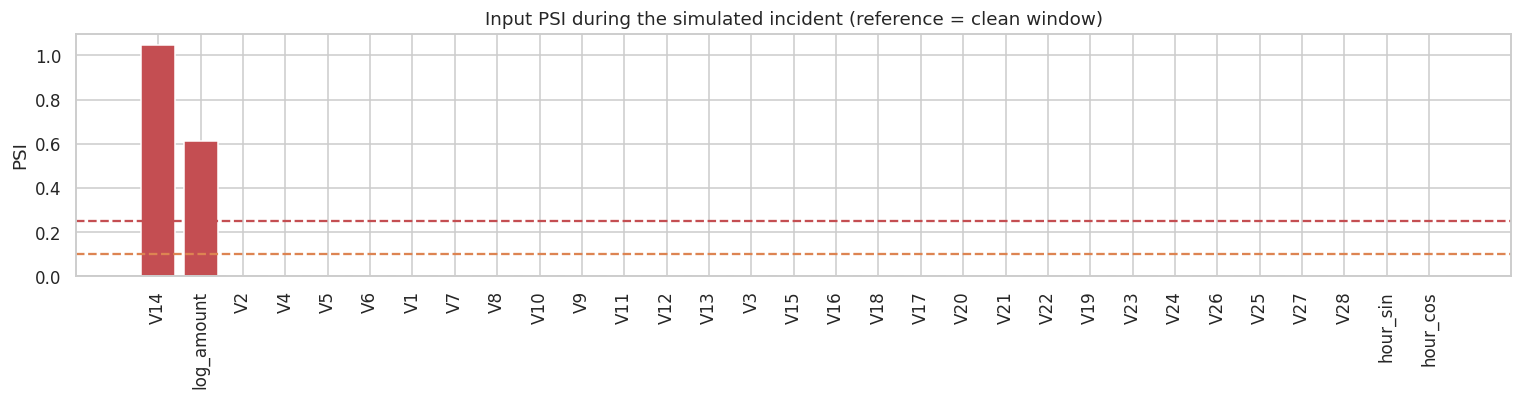

Features in ALERT (PSI > 0.25): {'V14': 1.046, 'log_amount': 0.614}


,clean window,incident window
mean fraud score,0.0012,0.0012
alert rate %,0.0952,0.1234
alerts,54.0000,70.0000


In [ ]:
X_inc = X_test.copy()
X_inc["Amount"] *= 3.0
X_inc["V14"] -= 0.8
X_inc_feat = FraudFeatures().transform(X_inc)

psi_inc = pd.Series({c: psi(make_reference(X_test_feat[c]), X_inc_feat[c]) for c in OUT_COLS}).sort_values(ascending=False)
p_inc = calibrated.predict_proba(X_inc)[:, 1]
alerts_clean = apply_policy(CHOSEN_POLICY, p_test, X_test["Amount"].values).mean()
alerts_inc = apply_policy(CHOSEN_POLICY, p_inc, X_inc["Amount"].values).mean()

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.bar(psi_inc.index, psi_inc.values, color=np.where(psi_inc > 0.25, "#C44E52", np.where(psi_inc > 0.10, "#DD8452", "#55A868")))
ax.axhline(0.10, ls="--", c="#DD8452"); ax.axhline(0.25, ls="--", c="#C44E52")
ax.set_ylabel("PSI"); ax.set_title("Input PSI during the simulated incident (reference = clean window)")
ax.tick_params(axis="x", rotation=90); plt.tight_layout(); plt.show()

output_monitor = pd.DataFrame({
    "clean window": [p_test.mean(), alerts_clean * 100, int(alerts_clean * len(X_test))],
    "incident window": [p_inc.mean(), alerts_inc * 100, int(alerts_inc * len(X_test))],
}, index=["mean fraud score", "alert rate %", "alerts"])
print("Features in ALERT (PSI > 0.25):", psi_inc[psi_inc > 0.25].round(3).to_dict())
output_monitor.round(4)

**Reading the monitor**

* Input PSI flags exactly the two changed signals: `log_amount` and `V14`. Every other feature stays green.
* On the **output** side, the mean score barely moves because almost every transaction still scores near zero. The
  **alert count**, however, rises by about 30 % (54 → 70): larger amounts lower the amount-aware threshold, and the
  shifted V14 pushes scores up. Operations would feel this at once as a longer review queue, weeks before chargebacks
  show what happened to recall. For rare-event models, the alert rate is a more sensitive output signal than the mean score.
* Alert on **effect sizes** (PSI), not p-values, which become "significant" for trivial shifts at
  this volume of transactions. Also correct for daily cycles before trusting any alarm (8.1).

**Closing the loop.** When score PSI or alert volume crosses its threshold, or delayed labels show recall falling, the loop
returns to Step 1: re-check the costs, pull fresh labelled data, retrain with the same pipeline, and promote the new model only
if it beats the current one on a recent out-of-time window.

In [ ]:
print("=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"Selected model        : {BEST_NAME} (+ Platt calibration)")
print(f"Decision policy       : {CHOSEN_POLICY}  (false-alarm cost €{C_FP:g}, miss cost = amount)")
for k, r in ci_table.iterrows():
    print(f"Test {k:<16s} : {r['estimate']:.3f}   95% CI [{r['95% CI low']:.3f}, {r['95% CI high']:.3f}]")
tp = test_policy.loc[CHOSEN_POLICY]
print(f"Test alerts           : {int(tp['alerts']):,} of {len(y_test):,} transactions ({tp['alerts']/len(y_test):.2%})")
print(f"Fraud value caught    : {tp['fraud € caught %']:.1f}% of fraud euros")
print(f"Artifacts             : {sorted(str(p) for p in ART.iterdir())}")

## Conclusions

* **Model.** A Random Forest on the 28 PCA components, plus log-amount and cyclical hour features, ranked frauds best
  on validation. Its lead over tuned gradient boosting, logistic regression and the MLP is **not statistically significant**
  (the bootstrap CI for the PR-AUC difference includes 0). Any of them would be defensible; logistic regression is the
  cheapest and most explainable runner-up.
* **Decision.** The amount-aware Bayes rule $t^*(x) = C_{FP}/(C_{FP}+\text{Amount})$, applied to calibrated probabilities,
  was the cheapest policy on validation without tuning anything. On the untouched test block it flags about 0.1 % of
  transactions with about 93 % precision, catches about two-thirds of frauds and about 69 % of fraud value, and cuts expected
  losses by about 69 % compared with having no model. The cost CI is wide (roughly 42–94 %) because the test block has only 74 frauds.
* **The default 0.5 threshold** catches nearly the same number of frauds but misses the expensive ones. It saves only about 49 %.
  Choosing the decision rule from the cost structure matters as much as choosing the model.
* **SMOTE (Section 6.3).** Tested as the third remedy for class imbalance, it gave no reliable ranking gain for the Random Forest,
  inflated its probabilities about 9×, and tripled training time. Re-weighting plus recalibration plus the cost-optimal threshold
  remains the approach. Done before splitting, SMOTE inflated ROC-AUC from 0.968 to 0.989. A paired cost bootstrap found
  no alternative reliably cheaper than the deployed model.
* **Production readiness.** The model is packaged as a decision function (features, model, calibration, policy and metadata)
  and loads in a fresh process. It has a scoring module, a FastAPI service, a model card and PSI monitoring with a same-hours reference window.

